# Homework 8

## 1. Supervised, Semi-Supervised, and Unsupervised Learning

### (a) 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

features = [
    "radius", "texture", "perimeter", "area", "smoothness",
    "compactness", "concavity", "concave_points",
    "symmetry", "fractal_dimension"
]

columns = ["id", "diagnosis"] + [
    f"{feature}_{stat}"
    for stat in ["mean", "se", "worst"]
    for feature in features
]

cancer = pd.read_csv("wdbc.data", header=None, names=columns)

X = cancer.drop(columns=["id", "diagnosis"])
y = cancer["diagnosis"].map({"B": 0, "M": 1})

print("Dataset shape:", cancer.shape)
print("Feature matrix shape:", X.shape)
print("\nClass counts (0 = benign, 1 = malignant):")
print(y.value_counts().sort_index())
print("\nMissing values:", cancer.isna().sum().sum())

cancer.head()

Dataset shape: (569, 32)
Feature matrix shape: (569, 30)

Class counts (0 = benign, 1 = malignant):
diagnosis
0    357
1    212
Name: count, dtype: int64

Missing values: 0


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### (b)
#### (i) 

In [2]:
from sklearn.model_selection import train_test_split

M = 30


def split_data(seed):
    return train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=seed
    )

# Keep class proportions when splitting the data.
X_train, X_test, y_train, y_test = split_data(seed=0)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

class_counts = pd.DataFrame({
    "Training": y_train.value_counts(),
    "Test": y_test.value_counts()
}).sort_index()

class_counts.index = ["Benign (0)", "Malignant (1)"]
class_counts

Training set: (455, 30)
Test set: (114, 30)


,Training,Test
Benign (0),285,72
Malignant (1),170,42


In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold

C_values = np.logspace(-3, 3, 7)


def fit_l1_svm(X_fit, y_fit, seed):
    # Fit the scaler within each CV fold to avoid data leakage.
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1",
            loss="squared_hinge",
            dual=False,
            max_iter=100000,
            random_state=seed
        ))
    ])

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    search = GridSearchCV(
        estimator=pipeline,
        param_grid={"svm__C": C_values},
        scoring="accuracy",
        cv=cv,
        n_jobs=-1
    )

    search.fit(X_fit, y_fit)
    return search


svm_search = fit_l1_svm(X_train, y_train, seed=0)
svm_model = svm_search.best_estimator_

print("Best C:", svm_search.best_params_["svm__C"])
print("Best CV accuracy:", round(svm_search.best_score_, 4))

Best C: 0.1
Best CV accuracy: 0.9802


In [4]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


def evaluate_model(model, X_data, y_true):
    y_pred = model.predict(X_data)
    y_score = model.decision_function(X_data)

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "AUC": roc_auc_score(y_true, y_score)
    }

train_metrics = evaluate_model(svm_model, X_train, y_train)
test_metrics = evaluate_model(svm_model, X_test, y_test)

single_run_results = pd.DataFrame(
    [train_metrics, test_metrics],
    index=["Training", "Test"]
)

single_run_results.round(4)

,Accuracy,Precision,Recall,F1,AUC
Training,0.9912,0.9940,0.9824,0.9882,0.9973
Test,0.9561,0.9302,0.9524,0.9412,0.9927


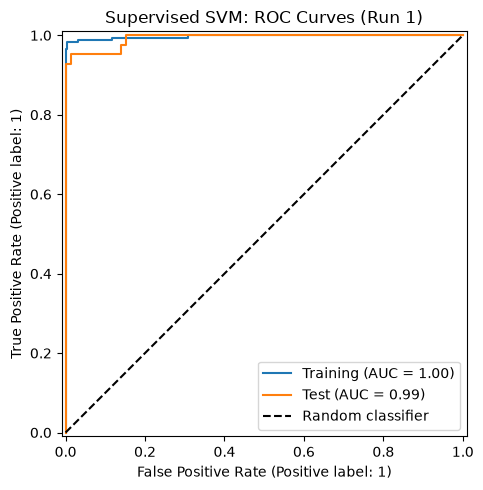

In [5]:
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 5))

for name, X_data, y_true in [
    ("Training", X_train, y_train),
    ("Test", X_test, y_test)
]:
    scores = svm_model.decision_function(X_data)

    RocCurveDisplay.from_predictions(y_true, scores, name=name, ax=ax)

ax.plot([0, 1], [0, 1], "k--", label="Random classifier")
ax.set_title("Supervised SVM: ROC Curves (Run 1)")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

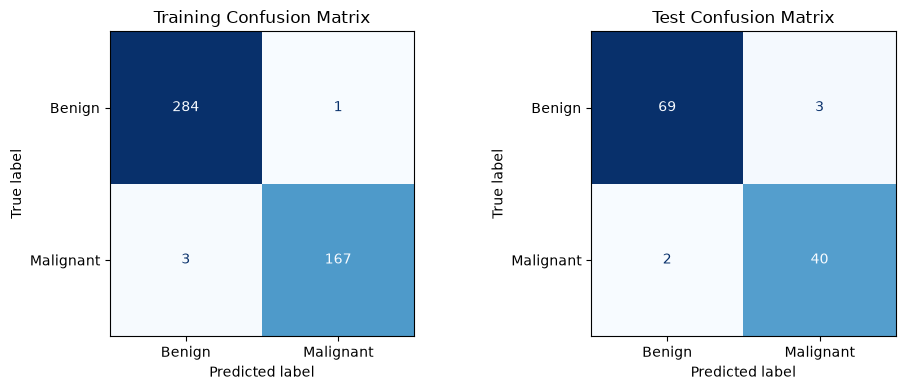

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, name, X_data, y_true in [
    (axes[0], "Training", X_train, y_train),
    (axes[1], "Test", X_test, y_test)
]:
    predictions = svm_model.predict(X_data)

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        predictions,
        labels=[0, 1],
        display_labels=["Benign", "Malignant"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(f"{name} Confusion Matrix")

plt.tight_layout()
plt.show()

In [7]:
supervised_records = []
supervised_best_C = []

for seed in range(M):
    X_tr, X_te, y_tr, y_te = split_data(seed)

    if seed == 0:
        search = svm_search
    else:
        search = fit_l1_svm(X_tr, y_tr, seed)

    model = search.best_estimator_
    supervised_best_C.append(search.best_params_["svm__C"])

    for name, X_data, y_true in [
        ("Training", X_tr, y_tr),
        ("Test", X_te, y_te)
    ]:
        metrics = evaluate_model(model, X_data, y_true)

        supervised_records.append({
            "Run": seed + 1,
            "Set": name,
            **metrics
        })

    if (seed + 1) % 5 == 0:
        print(f"Completed {seed + 1}/{M} runs")

supervised_results = pd.DataFrame(supervised_records)

metric_columns = ["Accuracy", "Precision", "Recall", "F1", "AUC"]

supervised_summary = (
    supervised_results
    .groupby("Set")[metric_columns]
    .mean()
    .reindex(["Training", "Test"])
)

supervised_summary.round(4)

Completed 5/30 runs
Completed 10/30 runs
Completed 15/30 runs
Completed 20/30 runs
Completed 25/30 runs
Completed 30/30 runs


,Accuracy,Precision,Recall,F1,AUC
Set,,,,,
Training,0.9864,0.9910,0.9725,0.9817,0.9973
Test,0.9667,0.9713,0.9381,0.9539,0.9932


#### (ii) 
##### A

In [8]:
def split_labeled_data(X_train, y_train, seed):
    labeled_idx, unlabeled_idx = train_test_split(
        np.arange(len(y_train)),
        train_size=0.5,
        stratify=y_train,
        random_state=seed
    )

    X_labeled = X_train.iloc[labeled_idx].copy()
    y_labeled = y_train.iloc[labeled_idx].copy()
    X_unlabeled = X_train.iloc[unlabeled_idx].copy()

    return X_labeled, y_labeled, X_unlabeled


# Match the first supervised split so the results are comparable.
X_train, X_test, y_train, y_test = split_data(seed=0)

X_labeled, y_labeled, X_unlabeled = split_labeled_data(
    X_train, y_train, seed=0
)

print("Labeled samples:", len(X_labeled))
print("Unlabeled samples:", len(X_unlabeled))
print("\nLabeled class counts:")
print(y_labeled.value_counts().sort_index())

Labeled samples: 227
Unlabeled samples: 228

Labeled class counts:
diagnosis
0    142
1     85
Name: count, dtype: int64


In [9]:
semi_search = fit_l1_svm(X_labeled, y_labeled, seed=0)
semi_model = semi_search.best_estimator_

print("Best C:", semi_search.best_params_["svm__C"])
print("Best CV accuracy:", round(semi_search.best_score_, 4))

Best C: 0.1
Best CV accuracy: 0.9557


##### B

In [10]:
from sklearn.base import clone


def self_train(initial_model, X_labeled, y_labeled, X_unlabeled,
               show_progress=False):
    X_known = X_labeled.copy()
    y_known = y_labeled.copy()
    X_pool = X_unlabeled.copy()

    model = clone(initial_model)
    model.fit(X_known, y_known)

    total = len(X_pool)

    for step in range(total):
        scores = model.decision_function(X_pool)
        position = np.argmax(np.abs(scores))

        # Add the most confident prediction, farthest from the SVM boundary.
        sample = X_pool.iloc[[position]]
        pseudo_label = model.predict(sample)[0]

        X_known = pd.concat([X_known, sample])
        y_known = pd.concat([
            y_known,
            pd.Series([pseudo_label], index=sample.index)
        ])

        X_pool = X_pool.drop(index=sample.index)

        # Retrain after adding each pseudo-label.
        model.fit(X_known, y_known)

        if show_progress and (
            (step + 1) % 50 == 0 or step + 1 == total
        ):
            print(f"Labeled {step + 1}/{total} samples")

    return model


semi_final_model = self_train(
    semi_model, X_labeled, y_labeled, X_unlabeled, show_progress=True
)

Labeled 50/228 samples
Labeled 100/228 samples
Labeled 150/228 samples
Labeled 200/228 samples
Labeled 228/228 samples


In [11]:
semi_single_run_results = pd.DataFrame(
    [
        evaluate_model(semi_final_model, X_train, y_train),
        evaluate_model(semi_final_model, X_test, y_test)
    ],
    index=["Training", "Test"]
)

semi_single_run_results.round(4)

,Accuracy,Precision,Recall,F1,AUC
Training,0.9846,0.9939,0.9647,0.9791,0.9970
Test,0.9386,0.9070,0.9286,0.9176,0.9901


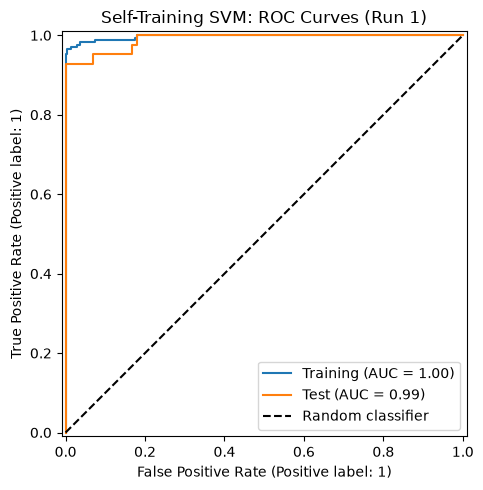

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))

for name, X_data, y_true in [
    ("Training", X_train, y_train),
    ("Test", X_test, y_test)
]:
    scores = semi_final_model.decision_function(X_data)

    RocCurveDisplay.from_predictions(y_true, scores, name=name, ax=ax)

ax.plot([0, 1], [0, 1], "k--", label="Random classifier")
ax.set_title("Self-Training SVM: ROC Curves (Run 1)")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

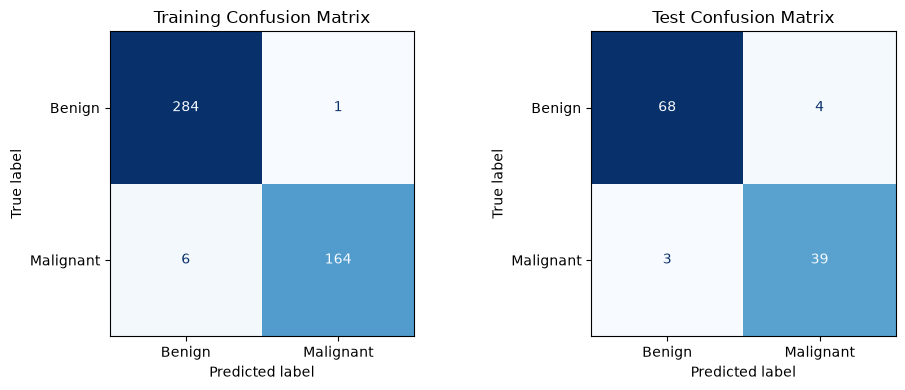

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, name, X_data, y_true in [
    (axes[0], "Training", X_train, y_train),
    (axes[1], "Test", X_test, y_test)
]:
    predictions = semi_final_model.predict(X_data)

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        predictions,
        labels=[0, 1],
        display_labels=["Benign", "Malignant"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(f"{name} Confusion Matrix")

plt.tight_layout()
plt.show()

In [14]:
semi_records = []
semi_best_C = []

for seed in range(M):
    X_tr, X_te, y_tr, y_te = split_data(seed)

    if seed == 0:
        search = semi_search
        model = semi_final_model
    else:
        X_lab, y_lab, X_unlab = split_labeled_data(X_tr, y_tr, seed)

        search = fit_l1_svm(X_lab, y_lab, seed)

        model = self_train(search.best_estimator_, X_lab, y_lab, X_unlab)

    semi_best_C.append(search.best_params_["svm__C"])

    for name, X_data, y_true in [
        ("Training", X_tr, y_tr),
        ("Test", X_te, y_te)
    ]:
        metrics = evaluate_model(model, X_data, y_true)

        semi_records.append({
            "Run": seed + 1,
            "Set": name,
            **metrics
        })

    print(f"Completed {seed + 1}/{M} runs")

semi_results = pd.DataFrame(semi_records)

semi_summary = (
    semi_results
    .groupby("Set")[metric_columns]
    .mean()
    .reindex(["Training", "Test"])
)

semi_summary.round(4)

Completed 1/30 runs
Completed 2/30 runs
Completed 3/30 runs
Completed 4/30 runs
Completed 5/30 runs
Completed 6/30 runs
Completed 7/30 runs
Completed 8/30 runs
Completed 9/30 runs
Completed 10/30 runs
Completed 11/30 runs
Completed 12/30 runs
Completed 13/30 runs
Completed 14/30 runs
Completed 15/30 runs
Completed 16/30 runs
Completed 17/30 runs
Completed 18/30 runs
Completed 19/30 runs
Completed 20/30 runs
Completed 21/30 runs
Completed 22/30 runs
Completed 23/30 runs
Completed 24/30 runs
Completed 25/30 runs
Completed 26/30 runs
Completed 27/30 runs
Completed 28/30 runs
Completed 29/30 runs
Completed 30/30 runs


,Accuracy,Precision,Recall,F1,AUC
Set,,,,,
Training,0.9771,0.9823,0.9565,0.9690,0.9948
Test,0.9635,0.9665,0.9341,0.9495,0.9912


In [15]:
svm_comparison = pd.concat(
    {
        "Supervised": supervised_summary,
        "Self-training": semi_summary
    },
    names=["Method", "Set"]
)

svm_comparison.round(4)

Accuracy  Precision  Recall      F1     AUC
Method        Set                                                  
Supervised    Training    0.9864     0.9910  0.9725  0.9817  0.9973
              Test        0.9667     0.9713  0.9381  0.9539  0.9932
Self-training Training    0.9771     0.9823  0.9565  0.9690  0.9948
              Test        0.9635     0.9665  0.9341  0.9495  0.9912

#### (iii)

In [16]:
from sklearn.cluster import KMeans


def fit_kmeans(X_train, seed):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_train)

    model = KMeans(
        n_clusters=2,
        init="random",
        n_init=50,
        max_iter=1000,
        random_state=seed
    )

    model.fit(X_scaled)
    return scaler, model


# Compare methods on the same first-run split.
X_train, X_test, y_train, y_test = split_data(seed=0)

km_scaler, kmeans_model = fit_kmeans(X_train, seed=0)

X_train_km = km_scaler.transform(X_train)
X_test_km = km_scaler.transform(X_test)

print("Inertia:", round(kmeans_model.inertia_, 4))
print("Cluster center shape:", kmeans_model.cluster_centers_.shape)

print("\nNumber of training samples in each cluster:")
print(
    pd.Series(kmeans_model.labels_, name="Cluster")
    .value_counts()
    .sort_index()
)

Inertia: 9216.6769
Cluster center shape: (2, 30)

Number of training samples in each cluster:
Cluster
0    310
1    145
Name: count, dtype: int64


C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


In [17]:
def label_kmeans_clusters(model, X_scaled, y_true):
    distances = model.transform(X_scaled)
    y_array = np.asarray(y_true)

    cluster_to_class = np.zeros(model.n_clusters, dtype=int)

    for cluster in range(model.n_clusters):
        # Let the 30 training points nearest each center vote on its class.
        nearest_indices = np.argsort(distances[:, cluster])[:30]
        nearest_labels = y_array[nearest_indices]

        votes = np.bincount(nearest_labels, minlength=2)
        cluster_to_class[cluster] = np.argmax(votes)

    return cluster_to_class


km_class_map = label_kmeans_clusters(
    kmeans_model, X_train_km, y_train
)

for cluster, label in enumerate(km_class_map):
    class_name = "Benign" if label == 0 else "Malignant"
    print(f"Cluster {cluster} -> {class_name} ({label})")

Cluster 0 -> Benign (0)
Cluster 1 -> Malignant (1)


In [18]:
# Map each cluster to the class chosen by the vote.
km_train_pred = km_class_map[kmeans_model.labels_]

# Use the nearest center to classify each test sample.
km_test_clusters = kmeans_model.predict(X_test_km)
km_test_pred = km_class_map[km_test_clusters]

print(
    "Training accuracy:",
    round(accuracy_score(y_train, km_train_pred), 4)
)

print(
    "Test accuracy:",
    round(accuracy_score(y_test, km_test_pred), 4)
)

Training accuracy: 0.9099
Test accuracy: 0.8772


In [19]:
from scipy.special import softmax


def predict_kmeans(model, X_scaled, class_map):
    distances = model.transform(X_scaled)

    cluster_ids = np.argmin(distances, axis=1)
    predictions = class_map[cluster_ids]

    # Weight nearby centers more heavily to get a score for the ROC curve.
    cluster_weights = softmax(-distances, axis=1)
    scores = cluster_weights @ class_map

    return predictions, scores


km_train_pred, km_train_score = predict_kmeans(
    kmeans_model, X_train_km, km_class_map
)

km_test_pred, km_test_score = predict_kmeans(
    kmeans_model, X_test_km, km_class_map
)

In [20]:
def evaluate_predictions(y_true, predictions, scores):
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "AUC": roc_auc_score(y_true, scores)
    }

km_single_run_results = pd.DataFrame(
    [
        evaluate_predictions(y_train, km_train_pred, km_train_score),
        evaluate_predictions(y_test, km_test_pred, km_test_score)
    ],
    index=["Training", "Test"]
)

km_single_run_results.round(4)

,Accuracy,Precision,Recall,F1,AUC
Training,0.9099,0.9448,0.8059,0.8698,0.9767
Test,0.8772,0.8333,0.8333,0.8333,0.9593


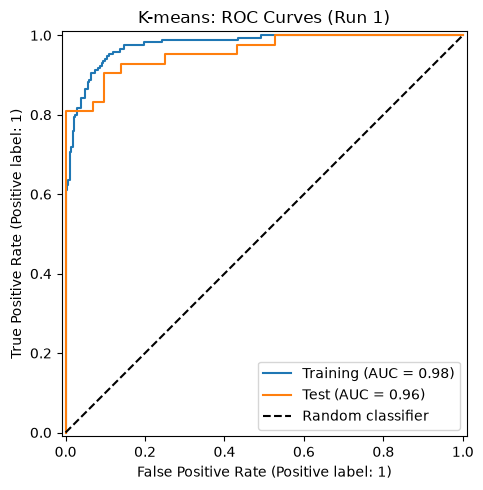

In [21]:
fig, ax = plt.subplots(figsize=(7, 5))

for name, y_true, scores in [
    ("Training", y_train, km_train_score),
    ("Test", y_test, km_test_score)
]:
    RocCurveDisplay.from_predictions(y_true, scores, name=name, ax=ax)

ax.plot([0, 1], [0, 1], "k--", label="Random classifier")
ax.set_title("K-means: ROC Curves (Run 1)")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

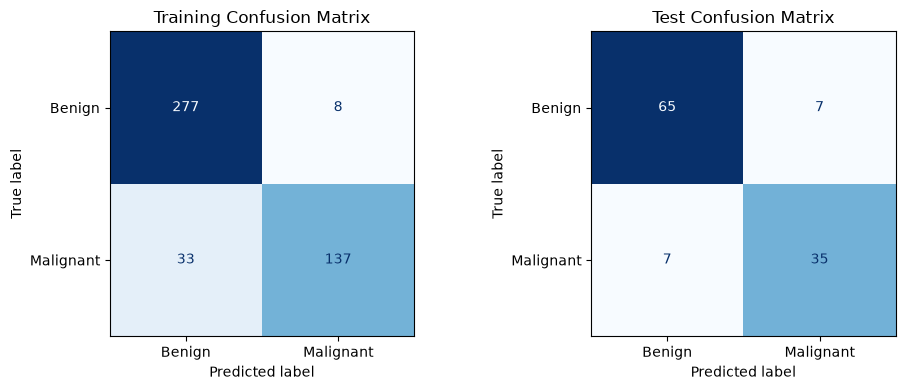

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, name, y_true, predictions in [
    (axes[0], "Training", y_train, km_train_pred),
    (axes[1], "Test", y_test, km_test_pred)
]:
    ConfusionMatrixDisplay.from_predictions(
        y_true,
        predictions,
        labels=[0, 1],
        display_labels=["Benign", "Malignant"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(f"{name} Confusion Matrix")

plt.tight_layout()
plt.show()

In [23]:
km_records = []

for seed in range(M):
    X_tr, X_te, y_tr, y_te = split_data(seed)

    if seed == 0:
        scaler = km_scaler
        model = kmeans_model
        class_map = km_class_map
    else:
        scaler, model = fit_kmeans(X_tr, seed)

        class_map = label_kmeans_clusters(
            model,
            scaler.transform(X_tr),
            y_tr
        )

    for name, X_data, y_true in [
        ("Training", X_tr, y_tr),
        ("Test", X_te, y_te)
    ]:
        predictions, scores = predict_kmeans(
            model,
            scaler.transform(X_data),
            class_map
        )

        metrics = evaluate_predictions(y_true, predictions, scores)

        km_records.append({
            "Run": seed + 1,
            "Set": name,
            **metrics
        })

    if (seed + 1) % 5 == 0:
        print(f"Completed {seed + 1}/{M} runs")

km_results = pd.DataFrame(km_records)

km_summary = (
    km_results
    .groupby("Set")[metric_columns]
    .mean()
    .reindex(["Training", "Test"])
)

km_summary.round(4)

C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

Completed 5/30 runs


C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

Completed 10/30 runs


C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

Completed 15/30 runs


... (4 outputs left out)

C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

Completed 30/30 runs


C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


,Accuracy,Precision,Recall,F1,AUC
Set,,,,,
Training,0.9102,0.9238,0.8282,0.8732,0.9749
Test,0.9053,0.9096,0.8262,0.8647,0.9719


In [24]:
comparison_so_far = pd.concat(
    {
        "Supervised": supervised_summary,
        "Self-training": semi_summary,
        "K-means": km_summary
    },
    names=["Method", "Set"]
)

comparison_so_far.round(4)

Accuracy  Precision  Recall      F1     AUC
Method        Set                                                  
Supervised    Training    0.9864     0.9910  0.9725  0.9817  0.9973
              Test        0.9667     0.9713  0.9381  0.9539  0.9932
Self-training Training    0.9771     0.9823  0.9565  0.9690  0.9948
              Test        0.9635     0.9665  0.9341  0.9495  0.9912
K-means       Training    0.9102     0.9238  0.8282  0.8732  0.9749
              Test        0.9053     0.9096  0.8262  0.8647  0.9719

#### (iv) 

In [25]:
from sklearn.cluster import SpectralClustering
from sklearn.preprocessing import MinMaxScaler


def fit_spectral(X_train, seed):
    scaler = MinMaxScaler()
    X_scaled = scaler.fit_transform(X_train)

    model = SpectralClustering(
        n_clusters=2,
        affinity="rbf",
        gamma=1.0,
        assign_labels="kmeans",
        n_init=50,
        random_state=seed
    )

    cluster_ids = model.fit_predict(X_scaled)

    return scaler, model, cluster_ids


# Keep the first-run split fixed across methods.
X_train, X_test, y_train, y_test = split_data(seed=0)

sp_scaler, spectral_model, sp_train_clusters = fit_spectral(
    X_train, seed=0
)

X_train_sp = sp_scaler.transform(X_train)
X_test_sp = sp_scaler.transform(X_test)

print("Number of training samples in each cluster:")
print(
    pd.Series(sp_train_clusters, name="Cluster")
    .value_counts()
    .sort_index()
)

Number of training samples in each cluster:
Cluster
0     94
1    361
Name: count, dtype: int64


C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


In [26]:
def label_spectral_clusters(cluster_ids, y_true):
    y_array = np.asarray(y_true)

    class_map = np.zeros(2, dtype=int)
    malignant_rates = np.zeros(2)
    records = []

    for cluster in range(2):
        labels = y_array[cluster_ids == cluster]

        votes = np.bincount(labels, minlength=2)
        class_map[cluster] = np.argmax(votes)
        # The malignant fraction is the score assigned to this cluster.
        malignant_rates[cluster] = labels.mean()

        records.append({
            "Cluster": cluster,
            "Benign": votes[0],
            "Malignant": votes[1],
            "Assigned class": class_map[cluster],
            "Malignant proportion": malignant_rates[cluster]
        })

    vote_table = pd.DataFrame(records).set_index("Cluster")

    return class_map, malignant_rates, vote_table


sp_class_map, sp_malignant_rates, sp_vote_table = (
    label_spectral_clusters(sp_train_clusters, y_train)
)

sp_vote_table.round(4)

,Benign,Malignant,Assigned class,Malignant proportion
Cluster,,,,
0,2,92,1,0.9787
1,283,78,0,0.2161


In [27]:
sp_train_pred = sp_class_map[sp_train_clusters]
sp_train_score = sp_malignant_rates[sp_train_clusters]

sp_train_metrics = evaluate_predictions(
    y_train, sp_train_pred, sp_train_score
)

pd.DataFrame([sp_train_metrics], index=["Training"]).round(4)

,Accuracy,Precision,Recall,F1,AUC
Training,0.8242,0.9787,0.5412,0.697,0.7671


In [28]:
def predict_spectral_transductive(
    model, X_train_scaled, X_test_scaled, y_train
):
    # Cluster train and test features together; use only training labels to vote.
    X_joint = np.vstack([X_train_scaled, X_test_scaled])

    joint_model = clone(model)
    joint_clusters = joint_model.fit_predict(X_joint)

    n_train = len(X_train_scaled)
    train_clusters = joint_clusters[:n_train]
    test_clusters = joint_clusters[n_train:]

    # Each cluster needs training members to determine its class.
    if len(np.unique(train_clusters)) != 2:
        raise ValueError(
            "A joint cluster has no training members, "
            "so its class cannot be determined from training labels."
        )

    class_map, malignant_rates, _ = label_spectral_clusters(
        train_clusters, y_train
    )

    predictions = class_map[test_clusters]
    scores = malignant_rates[test_clusters]

    return predictions, scores


sp_test_pred, sp_test_score = predict_spectral_transductive(
    spectral_model, X_train_sp, X_test_sp, y_train
)

C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


In [29]:
sp_test_metrics = evaluate_predictions(
    y_test, sp_test_pred, sp_test_score
)

sp_single_run_results = pd.DataFrame(
    [sp_train_metrics, sp_test_metrics],
    index=["Training", "Test (transductive)"]
)

sp_single_run_results.round(4)

,Accuracy,Precision,Recall,F1,AUC
Training,0.8242,0.9787,0.5412,0.6970,0.7671
Test (transductive),0.8860,1.0000,0.6905,0.8169,0.8452


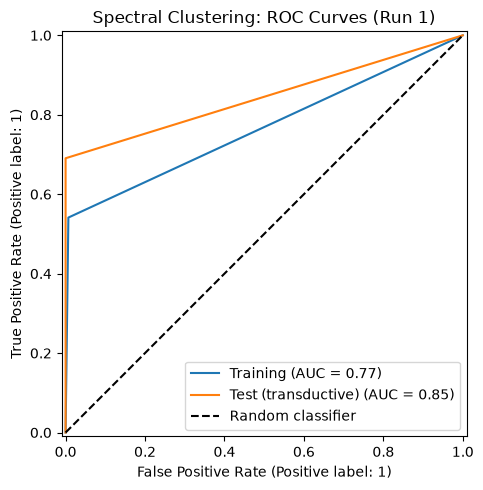

In [30]:
fig, ax = plt.subplots(figsize=(7, 5))

for name, y_true, scores in [
    ("Training", y_train, sp_train_score),
    ("Test (transductive)", y_test, sp_test_score)
]:
    RocCurveDisplay.from_predictions(y_true, scores, name=name, ax=ax)

ax.plot([0, 1], [0, 1], "k--", label="Random classifier")
ax.set_title("Spectral Clustering: ROC Curves (Run 1)")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

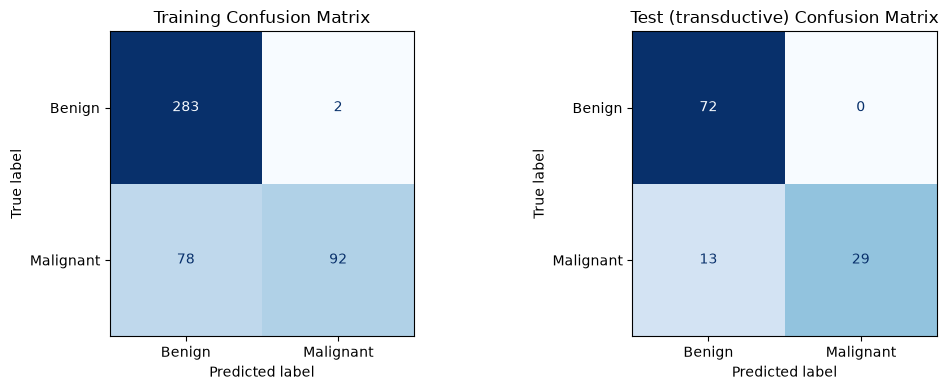

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, name, y_true, predictions in [
    (axes[0], "Training", y_train, sp_train_pred),
    (axes[1], "Test (transductive)", y_test, sp_test_pred)
]:
    ConfusionMatrixDisplay.from_predictions(
        y_true,
        predictions,
        labels=[0, 1],
        display_labels=["Benign", "Malignant"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(f"{name} Confusion Matrix")

plt.tight_layout()
plt.show()

In [32]:
sp_records = []

for seed in range(M):
    X_tr, X_te, y_tr, y_te = split_data(seed)

    if seed == 0:
        train_metrics = sp_train_metrics
        test_metrics = sp_test_metrics

    else:
        scaler, model, train_clusters = fit_spectral(X_tr, seed)

        X_tr_scaled = scaler.transform(X_tr)
        X_te_scaled = scaler.transform(X_te)

        # Score the clustering fitted on training data alone.
        class_map, malignant_rates, _ = label_spectral_clusters(
            train_clusters, y_tr
        )

        train_predictions = class_map[train_clusters]
        train_scores = malignant_rates[train_clusters]

        train_metrics = evaluate_predictions(
            y_tr, train_predictions, train_scores
        )

        # Recluster with test features included, keeping their labels hidden.
        test_predictions, test_scores = (
            predict_spectral_transductive(
                model,
                X_tr_scaled,
                X_te_scaled,
                y_tr
            )
        )

        test_metrics = evaluate_predictions(
            y_te, test_predictions, test_scores
        )

    for name, metrics in [
        ("Training", train_metrics),
        ("Test (transductive)", test_metrics)
    ]:
        sp_records.append({
            "Run": seed + 1,
            "Set": name,
            **metrics
        })

    print(f"Completed {seed + 1}/{M} runs")

sp_results = pd.DataFrame(sp_records)

sp_summary = (
    sp_results
    .groupby("Set")[metric_columns]
    .mean()
    .reindex(["Training", "Test (transductive)"])
)

sp_summary.round(4)

Completed 1/30 runs


C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


Completed 2/30 runs


C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


Completed 3/30 runs


C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


... (50 outputs left out)

Completed 29/30 runs


C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


Completed 30/30 runs


,Accuracy,Precision,Recall,F1,AUC
Set,,,,,
Training,0.8625,0.9802,0.6451,0.7770,0.8186
Test (transductive),0.8596,0.9795,0.6325,0.7675,0.8123


In [33]:
all_methods_summary = pd.concat(
    {
        "Supervised": supervised_summary,
        "Self-training": semi_summary,
        "K-means": km_summary,
        "Spectral": sp_summary
    },
    names=["Method", "Set"]
)

all_methods_summary.round(4)

Accuracy  Precision  Recall      F1     AUC
Method        Set                                                             
Supervised    Training               0.9864     0.9910  0.9725  0.9817  0.9973
              Test                   0.9667     0.9713  0.9381  0.9539  0.9932
Self-training Training               0.9771     0.9823  0.9565  0.9690  0.9948
              Test                   0.9635     0.9665  0.9341  0.9495  0.9912
K-means       Training               0.9102     0.9238  0.8282  0.8732  0.9749
              Test                   0.9053     0.9096  0.8262  0.8647  0.9719
Spectral      Training               0.8625     0.9802  0.6451  0.7770  0.8186
              Test (transductive)    0.8596     0.9795  0.6325  0.7675  0.8123

## 2. Active Learning Using Support Vector Machines

### (a)

In [34]:
bank_columns = ["variance", "skewness", "curtosis", "entropy", "class"]

banknotes = pd.read_csv(
    "data_banknote_authentication.txt",
    header=None,
    names=bank_columns
)

X_bank = banknotes.drop(columns="class")
y_bank = banknotes["class"]

print("Dataset shape:", banknotes.shape)
print("Missing values:", banknotes.isna().sum().sum())
print("\nClass counts:")
print(y_bank.value_counts().sort_index())

banknotes.head()

Dataset shape: (1372, 5)
Missing values: 0

Class counts:
class
0    762
1    610
Name: count, dtype: int64


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [35]:
X_bank_train, X_bank_test, y_bank_train, y_bank_test = (
    train_test_split(
        X_bank, y_bank, test_size=472, random_state=0
    )
)

# Use positional indices when drawing samples from the training pool.
X_bank_train = X_bank_train.reset_index(drop=True)
X_bank_test = X_bank_test.reset_index(drop=True)
y_bank_train = y_bank_train.reset_index(drop=True)
y_bank_test = y_bank_test.reset_index(drop=True)

print("Training pool:", X_bank_train.shape)
print("Test set:", X_bank_test.shape)

Training pool: (900, 4)
Test set: (472, 4)


### (b)
#### (i)

In [36]:
def make_bank_order(seed):
    rng = np.random.default_rng(seed)

    while True:
        order = rng.permutation(len(X_bank_train))
        initial_labels = y_bank_train.iloc[order[:10]]

        counts = np.bincount(
            initial_labels.to_numpy(dtype=int),
            minlength=2
        )

        # Start with five samples from each class for five-fold CV.
        if np.all(counts >= 5):
            return order

bank_order = make_bank_order(seed=0)
initial_indices = bank_order[:10]

X_initial = X_bank_train.iloc[initial_indices]
y_initial = y_bank_train.iloc[initial_indices]

print("Initial training samples:", len(X_initial))
print("\nInitial class counts:")
print(y_initial.value_counts().sort_index())

Initial training samples: 10

Initial class counts:
class
0    5
1    5
Name: count, dtype: int64


In [37]:
first_passive_search = fit_l1_svm(X_initial, y_initial, seed=0)

first_passive_model = first_passive_search.best_estimator_

bank_test_pred = first_passive_model.predict(X_bank_test)

first_passive_error = 1 - accuracy_score(y_bank_test, bank_test_pred)

print("Best C:", first_passive_search.best_params_["svm__C"])
print("Test error:", round(first_passive_error, 4))

Best C: 1000.0
Test error: 0.0953


In [38]:
training_sizes = np.arange(10, 901, 10)


def run_passive_learning(seed, first_search=None, show_progress=False):
    order = make_bank_order(seed)
    errors = []

    for size in training_sizes:
        selected = order[:size]

        X_pool = X_bank_train.iloc[selected]
        y_pool = y_bank_train.iloc[selected]

        if size == 10 and first_search is not None:
            search = first_search
        else:
            search = fit_l1_svm(X_pool, y_pool, seed)

        predictions = search.best_estimator_.predict(X_bank_test)

        error = 1 - accuracy_score(y_bank_test, predictions)
        errors.append(error)

        if show_progress and size % 100 == 0:
            print(f"Completed pool size: {size}/900")

    return np.array(errors)


passive_errors_run1 = run_passive_learning(
    seed=0,
    first_search=first_passive_search,
    show_progress=True
)

print("Number of test errors:", len(passive_errors_run1))

Completed pool size: 100/900
Completed pool size: 200/900
Completed pool size: 300/900
Completed pool size: 400/900
Completed pool size: 500/900
Completed pool size: 600/900
Completed pool size: 700/900
Completed pool size: 800/900
Completed pool size: 900/900
Number of test errors: 90


In [39]:
passive_run1_results = pd.DataFrame({
    "Training samples": training_sizes,
    "Test error": passive_errors_run1
})

passive_run1_results.iloc[[0, 1, 2, 9, 29, 49, 69, 89]].round(4)

,Training samples,Test error
0,10,0.0953
1,20,0.0275
2,30,0.0233
9,100,0.0339
29,300,0.0085
49,500,0.0148
69,700,0.0127
89,900,0.0127


In [40]:
n_runs = 50

passive_errors = np.zeros((n_runs, len(training_sizes)))

# Keep the first run already computed above.
passive_errors[0] = passive_errors_run1
print(f"Completed passive run 1/{n_runs}", flush=True)

for seed in range(1, n_runs):
    passive_errors[seed] = run_passive_learning(seed)

    print(
        f"Completed passive run {seed + 1}/{n_runs}",
        flush=True
    )

passive_mean_errors = passive_errors.mean(axis=0)

print("\nError array shape:", passive_errors.shape)
print("Mean error array shape:", passive_mean_errors.shape)

Completed passive run 1/50
Completed passive run 2/50
Completed passive run 3/50
Completed passive run 4/50
Completed passive run 5/50
Completed passive run 6/50
Completed passive run 7/50
Completed passive run 8/50
Completed passive run 9/50
Completed passive run 10/50
Completed passive run 11/50
Completed passive run 12/50
Completed passive run 13/50
Completed passive run 14/50
Completed passive run 15/50
Completed passive run 16/50
Completed passive run 17/50
Completed passive run 18/50
Completed passive run 19/50
Completed passive run 20/50
Completed passive run 21/50
Completed passive run 22/50
Completed passive run 23/50
Completed passive run 24/50
Completed passive run 25/50
Completed passive run 26/50
Completed passive run 27/50
Completed passive run 28/50
Completed passive run 29/50
Completed passive run 30/50
Completed passive run 31/50
Completed passive run 32/50
Completed passive run 33/50
Completed passive run 34/50
Completed passive run 35/50
Completed passive run 36/50
C

In [41]:
passive_summary = pd.DataFrame({
    "Training samples": training_sizes,
    "Mean test error": passive_mean_errors
})

passive_summary.iloc[[0, 1, 2, 9, 29, 49, 69, 89]].round(4)

,Training samples,Mean test error
0,10,0.1205
1,20,0.0656
2,30,0.0482
9,100,0.0221
29,300,0.0169
49,500,0.0154
69,700,0.0136
89,900,0.0132


#### (ii)

In [42]:
def run_active_learning(seed, first_search=None, show_progress=False):
    order = make_bank_order(seed)

    selected = order[:10].copy()
    remaining = order[10:].copy()

    errors = []

    for size in training_sizes:
        X_pool = X_bank_train.iloc[selected]
        y_pool = y_bank_train.iloc[selected]

        if size == 10 and first_search is not None:
            search = first_search
        else:
            search = fit_l1_svm(X_pool, y_pool, seed)

        model = search.best_estimator_

        predictions = model.predict(X_bank_test)
        error = 1 - accuracy_score(y_bank_test, predictions)
        errors.append(error)

        if show_progress and size % 100 == 0:
            print(f"Completed pool size: {size}/900", flush=True)

        if len(remaining) > 0:
            scores = model.decision_function(X_bank_train.iloc[remaining])

            # Query the 10 points with the smallest absolute SVM scores.
            closest_positions = np.argsort(np.abs(scores))[:10]
            new_indices = remaining[closest_positions]

            selected = np.concatenate([selected, new_indices])
            remaining = np.delete(remaining, closest_positions)

    return np.array(errors)


active_errors_run1 = run_active_learning(
    seed=0,
    first_search=first_passive_search,
    show_progress=True
)

print("Number of test errors:", len(active_errors_run1))

Completed pool size: 100/900
Completed pool size: 200/900
Completed pool size: 300/900
Completed pool size: 400/900
Completed pool size: 500/900
Completed pool size: 600/900
Completed pool size: 700/900
Completed pool size: 800/900
Completed pool size: 900/900
Number of test errors: 90


In [43]:
run1_comparison = pd.DataFrame({
    "Training samples": training_sizes,
    "Passive test error": passive_errors_run1,
    "Active test error": active_errors_run1
})

run1_comparison.iloc[[0, 1, 2, 9, 29, 49, 69, 89]].round(4)

,Training samples,Passive test error,Active test error
0,10,0.0953,0.0953
1,20,0.0275,0.0275
2,30,0.0233,0.0169
9,100,0.0339,0.0127
29,300,0.0085,0.0127
49,500,0.0148,0.0127
69,700,0.0127,0.0127
89,900,0.0127,0.0127


### (c)

In [44]:
active_errors = np.zeros((n_runs, len(training_sizes)))

# Keep the first run already computed above.
active_errors[0] = active_errors_run1
print(f"Completed active run 1/{n_runs}", flush=True)

for seed in range(1, n_runs):
    active_errors[seed] = run_active_learning(seed)

    print(
        f"Completed active run {seed + 1}/{n_runs}",
        flush=True
    )

active_mean_errors = active_errors.mean(axis=0)

print("\nError array shape:", active_errors.shape)
print("Mean error array shape:", active_mean_errors.shape)

Completed active run 1/50
Completed active run 2/50
Completed active run 3/50
Completed active run 4/50
Completed active run 5/50
Completed active run 6/50
Completed active run 7/50
Completed active run 8/50
Completed active run 9/50
Completed active run 10/50
Completed active run 11/50
Completed active run 12/50
Completed active run 13/50
Completed active run 14/50
Completed active run 15/50
Completed active run 16/50
Completed active run 17/50
Completed active run 18/50
Completed active run 19/50
Completed active run 20/50
Completed active run 21/50
Completed active run 22/50
Completed active run 23/50
Completed active run 24/50
Completed active run 25/50
Completed active run 26/50
Completed active run 27/50
Completed active run 28/50
Completed active run 29/50
Completed active run 30/50
Completed active run 31/50
Completed active run 32/50
Completed active run 33/50
Completed active run 34/50
Completed active run 35/50
Completed active run 36/50
Completed active run 37/50
Completed 

C:\Users\Saber\anaconda3\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Completed active run 41/50
Completed active run 42/50
Completed active run 43/50
Completed active run 44/50
Completed active run 45/50
Completed active run 46/50
Completed active run 47/50
Completed active run 48/50
Completed active run 49/50
Completed active run 50/50

Error array shape: (50, 90)
Mean error array shape: (90,)


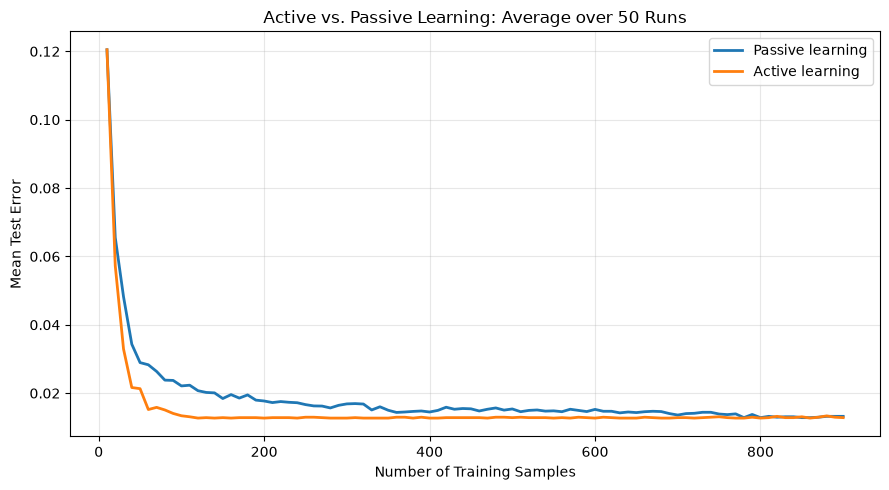

In [45]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    training_sizes,
    passive_mean_errors,
    label="Passive learning",
    linewidth=2
)

ax.plot(
    training_sizes,
    active_mean_errors,
    label="Active learning",
    linewidth=2
)

ax.set_xlabel("Number of Training Samples")
ax.set_ylabel("Mean Test Error")
ax.set_title("Active vs. Passive Learning: Average over 50 Runs")

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [46]:
learning_curve_summary = pd.DataFrame({
    "Training samples": training_sizes,
    "Passive mean error": passive_mean_errors,
    "Active mean error": active_mean_errors
})

learning_curve_summary.iloc[[0, 1, 2, 4, 9, 19, 29, 49, 69, 89]].round(4)

,Training samples,Passive mean error,Active mean error
0,10,0.1205,0.1205
1,20,0.0656,0.0573
2,30,0.0482,0.0329
4,50,0.0289,0.0213
9,100,0.0221,0.0134
19,200,0.0177,0.0127
29,300,0.0169,0.0127
49,500,0.0154,0.0128
69,700,0.0136,0.0128
89,900,0.0132,0.0128
